# Student Dropout Prediction: data preparation, EDA and model selection

**Problem.** For each enrolled student, predict whether they will end up as **Dropout**, still **Enrolled**,
or **Graduate**, using information known after the second semester (demographics, application details,
first- and second-semester course results, and economic context). A university could use the prediction as an
early-warning signal to offer support to students at risk.

**Data.** UCI ML Repository, *Predict Students' Dropout and Academic Success* (Realinho et al., 2021, CC BY 4.0).
The file is in `data/data.csv` (semicolon separated).

**Metric.** Three classes with unequal sizes, so accuracy alone can hide a weak minority class.
I optimize **macro-averaged F1** (the average of the three per-class F1 scores) and also report accuracy
and per-class precision and recall.

This notebook covers: cleaning and EDA, feature importance, training and tuning several models
(linear and tree-based), model selection with cross-validation, and a single final check on a held-out test set.
`train.py` then trains the selected model and saves it for `predict.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance

from common import (load_data, feature_lists, make_preprocessor, RANDOM_STATE)

sns.set_theme(style="whitegrid")

## 1. Data preparation

In [2]:
df = load_data()
print(df.shape)
df.head()

(4424, 37)


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Column names are cleaned in `common.load_data` (the source file has a trailing tab in one name and
misspells *Nacionality*). The target column is called `target`.

In [3]:
categorical, numerical = feature_lists(df)
print("Code columns (one-hot encoded):", len(categorical))
print("Numeric columns:              ", len(numerical))
print()
print("Missing values in total:", int(df.isnull().sum().sum()))
print("Duplicate rows:         ", int(df.duplicated().sum()))

Code columns (one-hot encoded): 9
Numeric columns:               27

Missing values in total: 0
Duplicate rows:          0


There are **no missing values and no duplicate rows**, so no imputation is needed.
Nine columns (marital status, application mode, course, previous qualification, nationality, and the
parents' qualification and occupation) hold *codes*. A code such as `course = 9991` is a label, not a quantity,
so those columns are one-hot encoded instead of being treated as numbers.

## 2. EDA

### 2.1 Ranges of the numeric columns

In [4]:
df[numerical].describe().T[["min", "mean", "max"]].round(2)

,min,mean,max
application_order,0.00,1.73,9.00
daytime_evening_attendance,0.00,0.89,1.00
previous_qualification_grade,95.00,132.61,190.00
admission_grade,95.00,126.98,190.00
displaced,0.00,0.55,1.00
educational_special_needs,0.00,0.01,1.00
debtor,0.00,0.11,1.00
tuition_fees_up_to_date,0.00,0.88,1.00
gender,0.00,0.35,1.00
scholarship_holder,0.00,0.25,1.00


In [5]:
# Number of distinct codes in each categorical column
df[categorical].nunique().sort_values(ascending=False)

fathers_occupation        46
fathers_qualification     34
mothers_occupation        32
mothers_qualification     29
nationality               21
application_mode          18
previous_qualification    17
course                    17
marital_status             6
dtype: int64

### 2.2 The target

,students,percent
target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


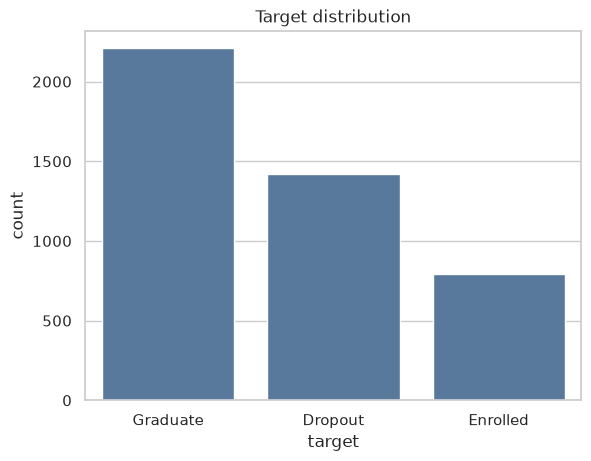

A model that always answers the most common class gets accuracy = 0.499


In [6]:
counts = df["target"].value_counts()
share = (counts / len(df) * 100).round(1)
display(pd.DataFrame({"students": counts, "percent": share}))

ax = sns.countplot(data=df, x="target", order=counts.index, color="#4c78a8")
ax.set_title("Target distribution"); plt.show()

print("A model that always answers the most common class gets accuracy =", round(counts.iloc[0] / len(df), 3))

The classes are unbalanced: **Enrolled** is the smallest group, and a model that always says "Graduate"
would already be right about half the time. That is why macro-F1 is the main metric: it only scores well
if all three classes are handled.

### 2.3 How the target relates to the features

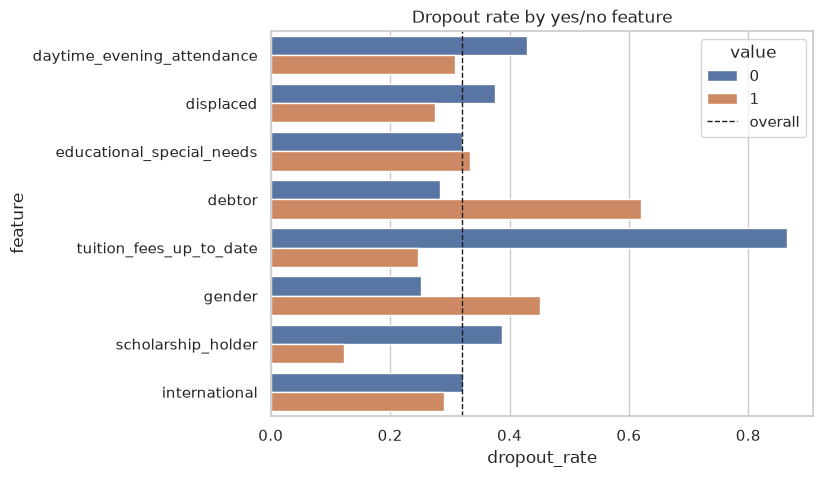

In [7]:
# Dropout rate for each yes/no flag (value 0 vs 1). See the UCI variable table for what each code means.
binary = [c for c in numerical if df[c].nunique() == 2]
is_dropout = (df["target"] == "Dropout")

rows = []
for c in binary:
    for value, rate in is_dropout.groupby(df[c]).mean().items():
        rows.append({"feature": c, "value": int(value), "dropout_rate": rate})
rates = pd.DataFrame(rows)

plt.figure(figsize=(7, 5))
sns.barplot(data=rates, y="feature", x="dropout_rate", hue="value", orient="h")
plt.axvline(is_dropout.mean(), color="k", ls="--", lw=1, label="overall")
plt.title("Dropout rate by yes/no feature"); plt.legend(title="value"); plt.show()

> Each yes/no column gets a pair of horizontal bars: blue is the group where the flag is 0 and orange is the group where it is 1. The length of a bar is the share of that group that ended as Dropout. The dashed vertical line is the overall dropout rate (about 32%), so a bar that reaches past the line means that group drops out more than average, and a bar that stops short means less. The gap between the two bars of a pair is the thing to look at.

- `tuition_fees_up_to_date` has the largest gap: about 86% of students who are *not* up to date (0) drop out, against about 25% of those who are (1).
- `debtor` points the same way: roughly 62% of debtors (1) drop out, against about 28% of the others.
- `scholarship_holder`: about 12% of scholarship holders drop out, against about 39% of the others.
- `gender` (1 = male in the UCI coding): about 45% for 1 against about 25% for 0.
- `daytime_evening_attendance` and `displaced` show a smaller gap: evening students (0) drop out about 43% of the time against about 31% for daytime students, and non-displaced students (0) about 37% against about 27% for displaced ones.
- `educational_special_needs` and `international` sit close to the overall line, so they show no clear pattern. 

target,Dropout,Enrolled,Graduate
curricular_units_1st_sem_approved,2.55,4.32,6.23
curricular_units_2nd_sem_approved,1.94,4.06,6.18
curricular_units_2nd_sem_grade,5.90,11.12,12.70
admission_grade,124.96,125.53,128.79
age_at_enrollment,26.07,22.37,21.78


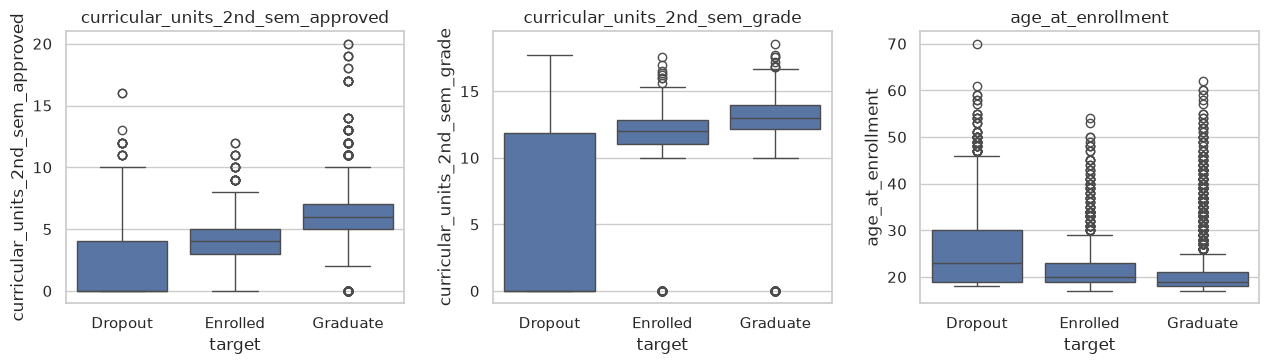

In [8]:
key = ["curricular_units_1st_sem_approved", "curricular_units_2nd_sem_approved",
       "curricular_units_2nd_sem_grade", "admission_grade", "age_at_enrollment"]
display(df.groupby("target")[key].mean().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c in zip(axes, ["curricular_units_2nd_sem_approved", "curricular_units_2nd_sem_grade", "age_at_enrollment"]):
    sns.boxplot(data=df, x="target", y=c, order=["Dropout", "Enrolled", "Graduate"], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

In [9]:
by_course = df.groupby("course")["target"].agg(
    students="size", dropout_rate=lambda s: (s == "Dropout").mean()).sort_values("dropout_rate")
by_course.round(2)

,students,dropout_rate
course,,
9500,766,0.15
9238,355,0.18
9070,226,0.23
9085,337,0.27
9773,331,0.31
8014,215,0.33
9147,380,0.35
9670,268,0.35
9254,252,0.38


Takeaways: students who keep up fees, hold a scholarship, and **pass more course units in the first two
semesters** are much less likely to drop out. Dropouts also tend to enroll at an older age, and the dropout rate
varies a lot between courses.

### 2.4 Feature importance, first look: mutual information

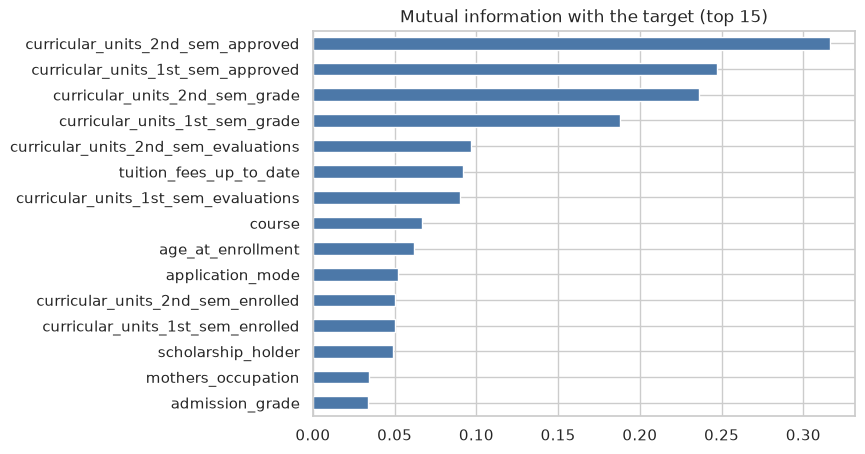

In [10]:
X_all = df.drop(columns="target")
discrete = [(c in categorical) or pd.api.types.is_integer_dtype(X_all[c]) for c in X_all.columns]
mi = pd.Series(mutual_info_classif(X_all, df["target"], discrete_features=discrete, random_state=RANDOM_STATE),
               index=X_all.columns).sort_values(ascending=False)

mi.head(15)[::-1].plot.barh(figsize=(7, 5), color="#4c78a8")
plt.title("Mutual information with the target (top 15)"); plt.show()

The most informative columns are the **second- and first-semester results** (units approved and grade).
Later, permutation importance on the trained model gives a second opinion.

## 3. Train / test split and cross-validation

20% of the students are held out as a **test set** that is used once, at the very end.
Models are compared with **stratified 5-fold cross-validation** on the remaining 80%, so class proportions are
kept in every fold. Preprocessing sits inside each pipeline, so every fold is encoded using its own training part only
(no leakage).

In [11]:
X = df.drop(columns="target")
y = df["target"]

X_full_train, X_test, y_full_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(len(X_full_train), "train rows,", len(X_test), "test rows")

def make_pipeline(estimator, scale=False):
    # scale=True standardizes numeric columns (required for the linear model)
    return Pipeline([("prep", make_preprocessor(categorical, numerical, scale=scale)),
                     ("model", estimator)])

3539 train rows, 885 test rows


## 4. Models and tuning

In [12]:
baseline = make_pipeline(DummyClassifier(strategy="most_frequent"))
print("Majority-class baseline, CV macro-F1:",
      round(cross_val_score(baseline, X_full_train, y_full_train, cv=cv, scoring="f1_macro").mean(), 3))

Majority-class baseline, CV macro-F1: 0.222


Four model families: a linear model (logistic regression) and three tree-based models (decision tree,
random forest, gradient boosting). Each is scored with default settings and then tuned with a grid search
(including `class_weight`, which makes mistakes on the small class cost more).

In [13]:
models = {
    "logistic_regression": (
        make_pipeline(LogisticRegression(max_iter=3000), scale=True),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "decision_tree": (
        make_pipeline(DecisionTreeClassifier(random_state=1)),
        {"model__max_depth": [4, 6, 8, 10], "model__min_samples_leaf": [10, 20, 50],
         "model__class_weight": [None, "balanced"]}),
    "random_forest": (
        make_pipeline(RandomForestClassifier(n_estimators=300, random_state=1, n_jobs=-1)),
        {"model__max_depth": [None, 12], "model__min_samples_leaf": [1, 3, 5],
         "model__class_weight": [None, "balanced_subsample"]}),
    "gradient_boosting": (
        make_pipeline(HistGradientBoostingClassifier(random_state=1)),
        {"model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 5],
         "model__max_iter": [100, 200], "model__min_samples_leaf": [20, 50],
         "model__class_weight": [None, "balanced"]}),
}

searches, rows = {}, []
for name, (pipeline, grid) in models.items():
    default_score = cross_val_score(pipeline, X_full_train, y_full_train, cv=cv,
                                    scoring="f1_macro", n_jobs=-1).mean()
    search = GridSearchCV(pipeline, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_full_train, y_full_train)
    searches[name] = search
    rows.append({"model": name, "default_cv_f1": default_score, "tuned_cv_f1": search.best_score_,
                 "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
    print(f"{name:20s} default {default_score:.4f} -> tuned {search.best_score_:.4f}")

results = pd.DataFrame(rows).sort_values("tuned_cv_f1", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", None)
results

logistic_regression  default 0.7008 -> tuned 0.7166


decision_tree        default 0.6239 -> tuned 0.6759


random_forest        default 0.6816 -> tuned 0.7210


gradient_boosting    default 0.7070 -> tuned 0.7318


,model,default_cv_f1,tuned_cv_f1,best_params
0,gradient_boosting,0.707043,0.731813,"{'class_weight': 'balanced', 'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 20}"
1,random_forest,0.681622,0.721009,"{'class_weight': 'balanced_subsample', 'max_depth': 12, 'min_samples_leaf': 3}"
2,logistic_regression,0.700779,0.716608,"{'C': 0.1, 'class_weight': 'balanced'}"
3,decision_tree,0.623902,0.675884,"{'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 50}"


## 5. Model selection

The winner is chosen by **cross-validated macro-F1 only**. The test set is not used to choose.
Differences of a few thousandths between models are within the noise of cross-validation, so if two
models are that close, a simpler one is reasonable too.

In [14]:
best_name = results.loc[0, "model"]
best_model = searches[best_name].best_estimator_      # already refit on the full training part
print("Selected model:", best_name)
print("Best parameters:", results.loc[0, "best_params"])

Selected model: gradient_boosting
Best parameters: {'class_weight': 'balanced', 'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 20}


### Final check on the held-out test set (used once)

Test macro-F1: 0.6898
Test accuracy: 0.7266

              precision    recall  f1-score   support

     Dropout      0.824     0.676     0.743       284
    Enrolled      0.413     0.642     0.502       159
    Graduate      0.862     0.790     0.824       442

    accuracy                          0.727       885
   macro avg      0.700     0.702     0.690       885
weighted avg      0.769     0.727     0.740       885



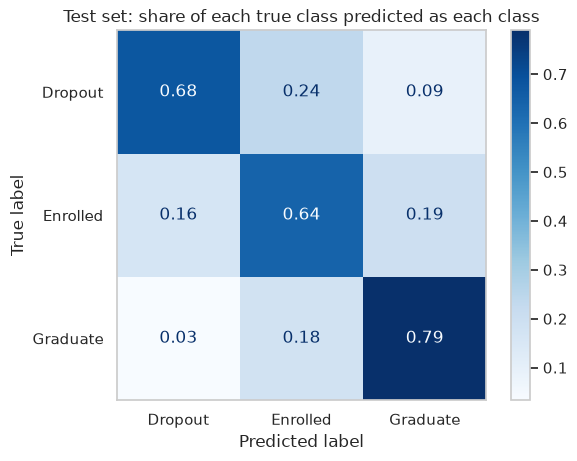

In [15]:
y_pred = best_model.predict(X_test)
print("Test macro-F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, digits=3))

disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", cmap="Blues", values_format=".2f")
disp.ax_.grid(False)
plt.title("Test set: share of each true class predicted as each class"); plt.show()

Reading the report: **Graduate** and **Dropout** are predicted reasonably well; **Enrolled** is the hardest class,
because those students sit between the other two outcomes. This is the main limitation of the model.

## 6. Feature importance of the final model (permutation importance)

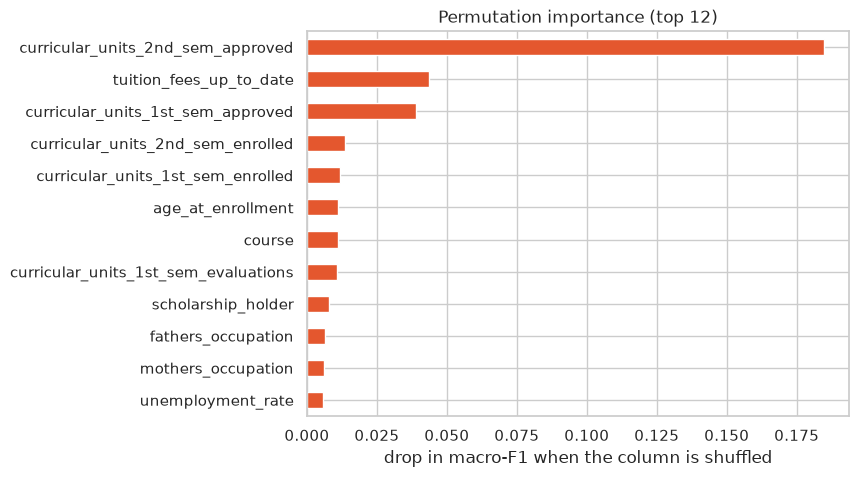

curricular_units_2nd_sem_approved       0.1846
tuition_fees_up_to_date                 0.0436
curricular_units_1st_sem_approved       0.0390
curricular_units_2nd_sem_enrolled       0.0135
curricular_units_1st_sem_enrolled       0.0117
age_at_enrollment                       0.0111
course                                  0.0110
curricular_units_1st_sem_evaluations    0.0109
scholarship_holder                      0.0077
fathers_occupation                      0.0065
mothers_occupation                      0.0061
unemployment_rate                       0.0059
dtype: float64

In [16]:
# Fit the selected configuration on 75% of the training part, then measure on the other 25%:
# shuffle one original column at a time and see how much macro-F1 drops.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_full_train, y_full_train, test_size=0.25, stratify=y_full_train, random_state=RANDOM_STATE)
est = clone(best_model).fit(X_tr, y_tr)

perm = permutation_importance(est, X_val, y_val, scoring="f1_macro", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_val.columns).sort_values(ascending=False)

imp.head(12)[::-1].plot.barh(figsize=(7, 5), color="#e4572e")
plt.xlabel("drop in macro-F1 when the column is shuffled")
plt.title("Permutation importance (top 12)"); plt.show()
imp.head(12).round(4)

The number of course units passed in the **second semester** matters far more than anything else
(shuffling it costs the model about 0.18 macro-F1). Tuition status and first-semester units passed come next,
followed by smaller contributions from units enrolled, age at enrollment and course. Mutual information (section 2.4)
puts the same group of features at the top, so both methods agree.

## 7. Hand-off to `train.py`

`train.py` trains the selected configuration (parameters printed in section 5) on the same train split, reports the same metrics, and saves the model with `joblib`. See the README for how to run it.

**Limitations.** 

1. The most useful features are second-semester results, so predictions are available only after the second semester.

2. Enrolled students are hard to separate from the other two groups. (3) The data comes from one Portuguese institution, so the model should not be assumed to transfer to other schools without re-checking.